# 02 · Exploratory data analysis

**Goal.** Look at the data before modelling: how many rows each category has, what the descriptions
look like, how amounts and dates behave, and what is missing or duplicated. Every modelling
decision later should trace back to something seen here.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import matplotlib.pyplot as plt
import seaborn as sns

# One quiet style for every chart: light grid, no top/right frame, grey text.
sns.set_theme(style="whitegrid", rc={
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e", "xtick.color": "#52514e",
    "ytick.color": "#52514e", "grid.color": "#ebeae6", "axes.spines.top": False,
    "axes.spines.right": False, "axes.titleweight": "bold", "axes.titlesize": 12,
    "figure.dpi": 110})

import re
from collections import Counter

import numpy as np
import pandas as pd

from src import config, data

household = data.load_source("household")
personal = data.load_source("personal_finance")
own = data.load_source("own")
everything = pd.concat([household, personal, own], ignore_index=True)
print({name: len(df) for name, df in [("household", household), ("personal_finance", personal), ("own", own)]})

[map] household: dropped 444 of 2176 rows with no matching category
[clean] removed 159 empty-description rows and 0 exact duplicates
[map] personal_finance: dropped 84 of 688 rows with no matching category
[clean] removed 0 empty-description rows and 0 exact duplicates
[clean] removed 0 empty-description rows and 0 exact duplicates
{'household': 1573, 'personal_finance': 604, 'own': 5}


## Missing values and duplicates (raw files, before cleaning)

In [2]:
raw_household = pd.read_csv(config.HOUSEHOLD_CSV)
raw_personal = pd.read_csv(config.PERSONAL_FINANCE_CSV)
quality = pd.DataFrame({
    "rows": [len(raw_household), len(raw_personal)],
    "missing description": [raw_household["Note"].isna().sum(), raw_personal["Description"].isna().sum()],
    "missing subcategory": [raw_household["Subcategory"].isna().sum(), np.nan],
    "exact duplicate rows": [raw_household.duplicated().sum(), raw_personal.duplicated().sum()],
}, index=["household (raw)", "personal_finance (raw)"])
display(quality)
print("Missing values per column, household raw:")
print(raw_household.isna().sum().to_string())
print(f"\nAfter cleaning: {everything.isna().sum().sum()} missing values, "
      f"{everything.duplicated(subset=data.COLUMNS).sum()} exact duplicates")

,rows,missing description,missing subcategory,exact duplicate rows
household (raw),2461,521,635.0,9
personal_finance (raw),806,0,NaN,0


Missing values per column, household raw:
Date                0
Mode                0
Category            0
Subcategory       635
Note              521
Amount              0
Income/Expense      0
Currency            0

After cleaning: 0 missing values, 0 exact duplicates


## Chart 1 · Rows per category (class balance)

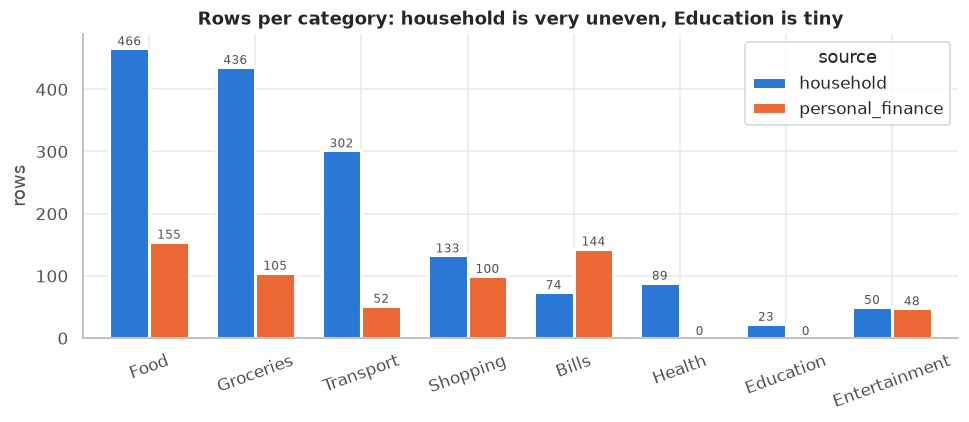

source,household,personal_finance,household_share
category,,,
Food,466,155,0.296
Groceries,436,105,0.277
Transport,302,52,0.192
Shopping,133,100,0.085
Bills,74,144,0.047
Health,89,0,0.057
Education,23,0,0.015
Entertainment,50,48,0.032


In [3]:
counts = (everything[everything.source != "own"]
          .groupby(["category", "source"]).size().unstack(fill_value=0)
          .reindex(config.CATEGORIES, fill_value=0))
ax = counts.plot.bar(figsize=(9, 4), width=0.75, color=[config.SOURCE_COLORS[s] for s in counts.columns],
                     edgecolor="white", linewidth=2)
ax.set_title("Rows per category: household is very uneven, Education is tiny")
ax.set_xlabel(""); ax.set_ylabel("rows"); ax.tick_params(axis="x", rotation=20)
for container in ax.containers:
    ax.bar_label(container, fontsize=8, color="#52514e")
plt.tight_layout(); plt.show()
display(counts.assign(household_share=(counts["household"] / counts["household"].sum()).round(3)))

## Chart 2 · Rows per source

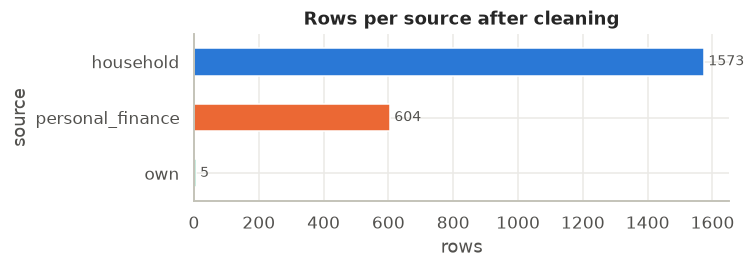

In [4]:
per_source = everything.source.value_counts()
ax = per_source.plot.barh(figsize=(7, 2.6), color=[config.SOURCE_COLORS[s] for s in per_source.index])
ax.set_title("Rows per source after cleaning"); ax.set_xlabel("rows"); ax.invert_yaxis()
ax.bar_label(ax.containers[0], padding=3, fontsize=9, color="#52514e")
plt.tight_layout(); plt.show()

## Chart 3 · Amount per category (household only, INR, log scale)

Only one currency per chart: adding or comparing INR with USD or PKR would be meaningless.

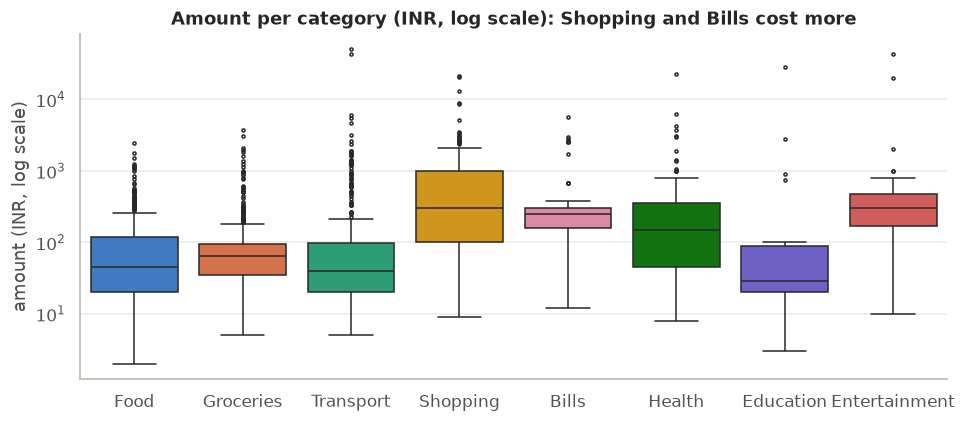

,count,25%,50%,75%,max
category,,,,,
Food,466.0,20.0,45.0,119.0,2421.0
Groceries,436.0,35.0,64.0,96.0,3750.0
Transport,302.0,20.0,40.0,99.0,50000.0
Shopping,133.0,100.0,300.0,989.0,21500.0
Bills,74.0,157.0,251.0,301.0,5640.0
Health,89.0,45.0,150.0,354.0,22700.0
Education,23.0,20.0,29.0,88.0,28400.0
Entertainment,50.0,169.0,298.0,482.0,43000.0


In [5]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.boxplot(data=household, x="category", y="amount", order=config.CATEGORIES, hue="category",
            palette=config.CATEGORY_COLORS, legend=False, fliersize=2, ax=ax)
ax.set_yscale("log"); ax.set_title("Amount per category (INR, log scale): Shopping and Bills cost more")
ax.set_xlabel(""); ax.set_ylabel("amount (INR, log scale)")
plt.tight_layout(); plt.show()
household.groupby("category").amount.describe()[["count", "25%", "50%", "75%", "max"]].reindex(config.CATEGORIES).round(0)

## Chart 4 · Description length

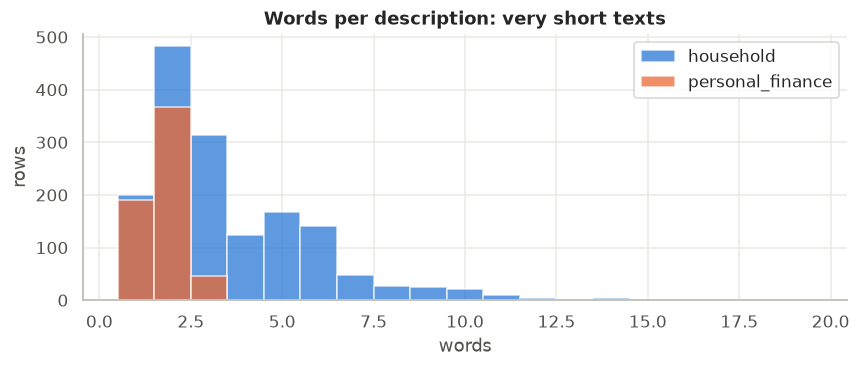

                   count  mean   std  min  25%  50%  75%   max
source                                                        
household         1573.0  3.55  2.34  1.0  2.0  3.0  5.0  19.0
own                  5.0  5.00  1.41  3.0  4.0  6.0  6.0   6.0
personal_finance   604.0  1.76  0.58  1.0  1.0  2.0  2.0   3.0
household: 43% of descriptions contain a digit, 893 unique descriptions out of 1573
personal_finance: 0% of descriptions contain a digit, 62 unique descriptions out of 604


In [6]:
everything["words"] = everything.description.str.split().str.len()
fig, ax = plt.subplots(figsize=(8, 3.5))
for source in ["household", "personal_finance"]:
    subset = everything[everything.source == source]
    ax.hist(subset.words, bins=np.arange(0.5, 20.5, 1), alpha=0.75, label=source,
            color=config.SOURCE_COLORS[source], edgecolor="white")
ax.set_title("Words per description: very short texts"); ax.set_xlabel("words"); ax.set_ylabel("rows")
ax.legend(); plt.tight_layout(); plt.show()
print(everything.groupby("source").words.describe().round(2).to_string())
for name, df in [("household", household), ("personal_finance", personal)]:
    print(f"{name}: {df.description.str.contains(r'[0-9]').mean():.0%} of descriptions contain a digit, "
          f"{df.description.nunique()} unique descriptions out of {len(df)}")

## Chart 5 · Top 10 words per category (household)

Words are only lower-cased here, nothing removed, so we can see what the noise looks like.

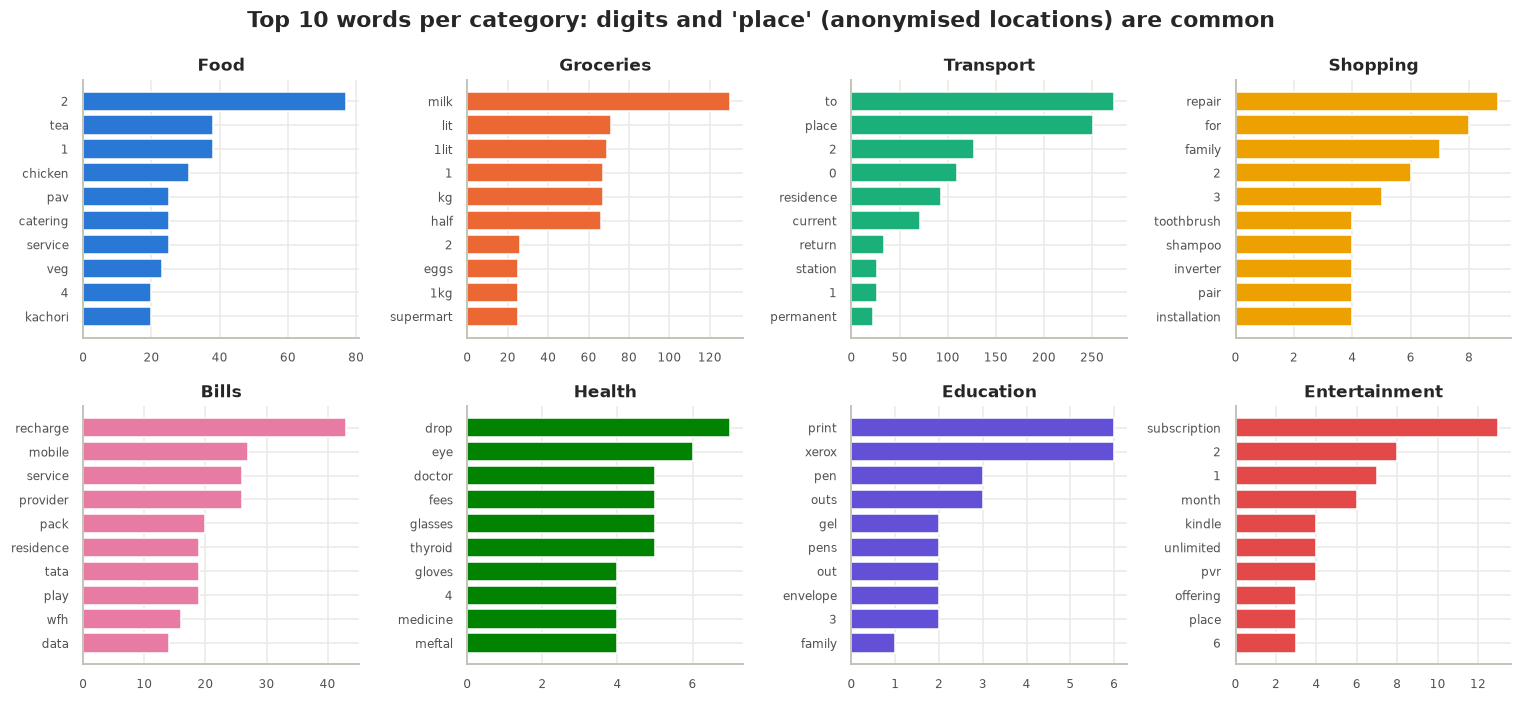

Descriptions containing 'place': 194, of which Transport: 188


In [7]:
def words(text: str) -> list[str]:
    return re.findall(r"[a-z0-9]+", text.lower())

fig, axes = plt.subplots(2, 4, figsize=(14, 6.5))
for ax, category in zip(axes.flat, config.CATEGORIES):
    top = Counter(w for t in household[household.category == category].description for w in words(t)).most_common(10)
    labels, values = zip(*top)
    ax.barh(labels[::-1], values[::-1], color=config.CATEGORY_COLORS[category])
    ax.set_title(category, fontsize=11); ax.tick_params(labelsize=8)
fig.suptitle("Top 10 words per category: digits and 'place' (anonymised locations) are common", fontweight="bold")
plt.tight_layout(); plt.show()
place = household.description.str.lower().str.contains("place")
print(f"Descriptions containing 'place': {place.sum()}, of which Transport: {(place & (household.category == 'Transport')).sum()}")

## Chart 6 · Spending by weekday (household, INR)

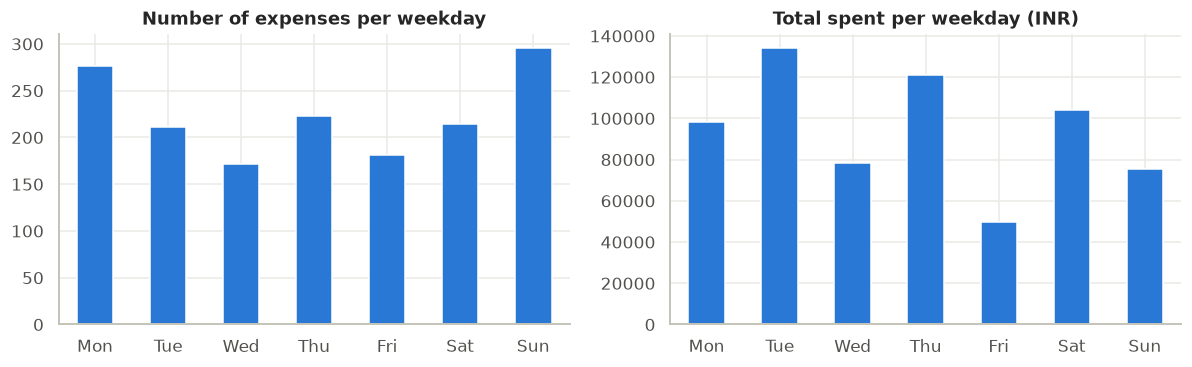

category  Bills  Education  Entertainment  Food  Groceries  Health  Shopping  Transport
weekend                                                                                
False      0.05       0.02           0.03   0.3       0.30    0.05      0.08       0.17
True       0.04       0.01           0.03   0.3       0.24    0.06      0.09       0.24


In [8]:
weekday_names = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
by_day = household.groupby(household.date.dt.day_of_week).agg(rows=("amount", "size"), total_inr=("amount", "sum"))
by_day.index = weekday_names
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
by_day.rows.plot.bar(ax=axes[0], color="#2a78d6"); axes[0].set_title("Number of expenses per weekday")
by_day.total_inr.plot.bar(ax=axes[1], color="#2a78d6"); axes[1].set_title("Total spent per weekday (INR)")
for ax in axes: ax.tick_params(axis="x", rotation=0); ax.set_xlabel("")
plt.tight_layout(); plt.show()
weekend = household.date.dt.day_of_week >= 5
print(household.assign(weekend=weekend).groupby("weekend").category.value_counts(normalize=True).unstack().round(2).to_string())

## Chart 7 · Rows per month

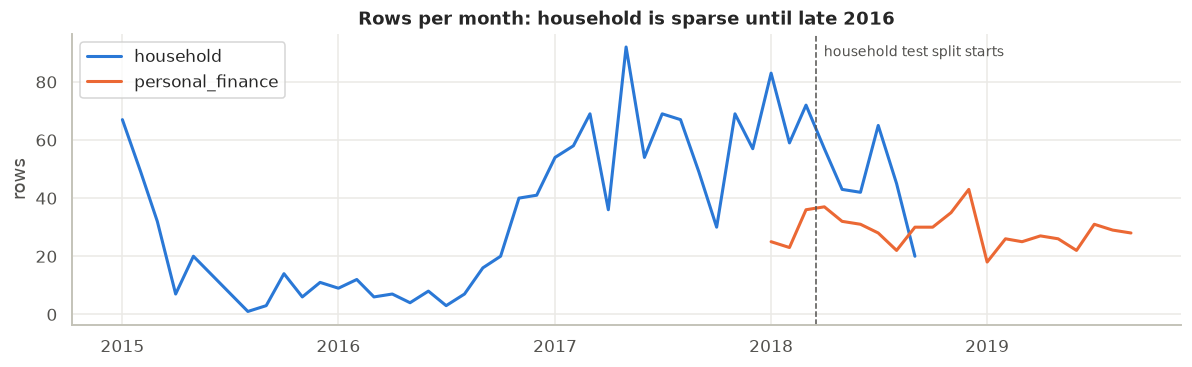

Household rows before 2016-10: 282, from 2016-10: 1291


In [9]:
monthly = (everything[everything.source != "own"]
           .groupby([everything.date.dt.to_period("M"), "source"]).size().unstack())
# Months with no rows for a source stay empty (NaN) rather than 0, so lines stop where data stops.
monthly.index = monthly.index.to_timestamp()
fig, ax = plt.subplots(figsize=(11, 3.5))
for source in monthly.columns:
    ax.plot(monthly.index, monthly[source], color=config.SOURCE_COLORS[source], linewidth=2, label=source)
train, test = data.time_split(household)
ax.axvline(test.date.min(), color="#52514e", linestyle="--", linewidth=1)
ax.text(test.date.min(), ax.get_ylim()[1] * 0.92, "  household test split starts", fontsize=9, color="#52514e")
ax.set_title("Rows per month: household is sparse until late 2016"); ax.set_ylabel("rows"); ax.legend()
plt.tight_layout(); plt.show()
print(f"Household rows before 2016-10: {(household.date < '2016-10-01').sum()}, from 2016-10: {(household.date >= '2016-10-01').sum()}")

## Chart 8 · Does the test period look like the training period?

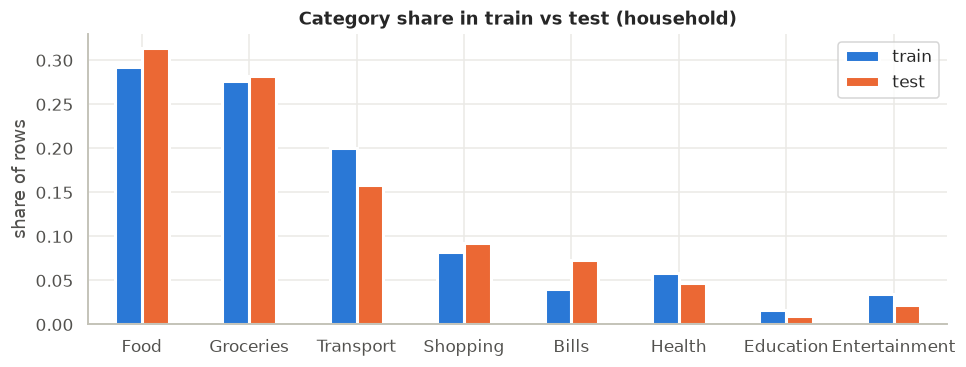

60% of test descriptions appear word-for-word in training


,train,test
category,,
Food,0.292,0.314
Groceries,0.276,0.283
Transport,0.200,0.159
Shopping,0.083,0.092
Bills,0.041,0.073
Health,0.059,0.048
Education,0.016,0.010
Entertainment,0.034,0.022


In [10]:
mix = pd.DataFrame({"train": train.category.value_counts(normalize=True),
                    "test": test.category.value_counts(normalize=True)}).reindex(config.CATEGORIES)
ax = mix.plot.bar(figsize=(9, 3.5), color=["#2a78d6", "#eb6834"], edgecolor="white", linewidth=2)
ax.set_title("Category share in train vs test (household)"); ax.set_ylabel("share of rows")
ax.tick_params(axis="x", rotation=0); ax.set_xlabel(""); plt.tight_layout(); plt.show()
seen = test.description.str.lower().isin(set(train.description.str.lower()))
print(f"{seen.mean():.0%} of test descriptions appear word-for-word in training")
display(mix.round(3))

## Findings

- **Missing and duplicate data.** 521 of 2,461 raw household rows (21%) have no description and 9 are exact duplicates. After cleaning there are 0 missing values and 0 duplicates.
- **Class imbalance.** In household data Food (30%) and Groceries (28%) dominate; Education has only 23 rows (1.5%), Entertainment 50.
- **Two very different text styles.** Household notes are short free text (median 3 words; 43% contain a digit such as "2 plates" or "1lit"). Personal-finance descriptions are merchant names (62 unique values, about 2 words, no digits) and contain no Health or Education rows.
- **Digits and units are noise.** The top words in Food and Groceries include "2", "1", "lit" and "kg": quantities, not categories.
- **A dataset artefact.** Locations were anonymised to "Place 0", "Place 4"...: 194 descriptions contain "place" and 188 of them are Transport. This will help on the household test split but will not exist in a student's own data.
- **Amounts differ by category.** Median Transport is 40 INR, Groceries 64, Shopping 300; every category has a long tail (Transport up to 50,000 INR).
- **Weekends look a little different.** Transport is 24% of weekend rows vs 17% on weekdays; Groceries 24% vs 30%.
- **Time.** Household data is sparse before October 2016 (282 rows) and dense after (1,291). The test period's category mix is close to training, but Bills rises from 4.1% to 7.3%.
- **The test split is partly "easy".** 60% of test descriptions appear word-for-word in training, so the own-expenses test will be the harder, more honest check.

### Decisions this EDA led to

1. **`clean_text` lower-cases and strips digits and punctuation** (Chart 5), so "2 plates" and "1 plate" become the same text.
2. **Use `log1p(amount)`, not raw amount** (Chart 3): amounts span 1 to 50,000, and the log keeps one big purchase from dominating. Amounts stay in their own currency and are never added across currencies.
3. **Choose models by macro-F1 and try `class_weight="balanced"`** (Chart 1), so rare categories like Education count.
4. **Add `weekday` and `is_weekend` features** (Chart 6): a small but real difference.
5. **TF-IDF with 1–2-word phrases and `min_df=2`** (Charts 4 and 5): texts are short and repeat a lot, and pairs like "place to" or "mobile recharge" carry more meaning than single words.
6. **Report transfer results separately** (Charts 1, 4, 5): the personal-finance data has different wording, currency and categories, so a drop there is expected and must be explained, not hidden.

## What I learned